# PULSO · Quantas pessoas podem depender de alertas que não sejam só sonoros ou visuais?
**Um retrato descritivo com o Censo Demográfico 2022 (IBGE)**

**Global Solution 2026.2 · FIAP · Engenharia de Software · Data Science & Statistical Computing**  
**Aluno:** Cainã Sandes Batista · **RM:** 568571 · **Turma:** 2ESPR · Projeto: PULSO

## Objetivos do PULSO
1. Promover maior autonomia de pessoas surdas, cegas e surdocegas durante a espera por atendimento presencial;
2. Reduzir o risco de chamadas não percebidas por meio de alertas sensoriais adaptados às preferências de cada pessoa;
3. Oferecer uma alternativa portátil e acessível de comunicação, sem depender de internet ou de equipamentos próprios dos estabelecimentos.

O PULSO é um dispositivo físico e offline (pulseira e transmissor ESP32). Este notebook é uma **análise acadêmica complementar**: não faz parte do dispositivo e não usa dados dele.

## 1. Contexto e perguntas

Pessoas surdas, cegas e surdocegas podem não perceber que foram chamadas em locais que anunciam por voz ou por painel. As evidências sobre essa barreira que reunimos são **qualitativas ou amostrais e de outros contextos**: o relato de uma moradora surda do Itaim Paulista (Agência Mural, 2020), um estudo qualitativo com 11 pessoas surdas em Goiânia (Cardoso et al., 2006), um estudo qualitativo em Ontário (CMAJ, 2026) e uma pesquisa online na Escócia com 118 respondentes, em que 71% relataram barreiras ao serem chamados da sala de espera (RNID, 2025). Essas fontes **não são analisadas aqui**.

Falta uma pergunta anterior: **de que tamanho é o grupo de pessoas que declara muita dificuldade ou incapacidade para ouvir ou enxergar no Brasil, e como ele se distribui?** O Censo 2022 responde a isso. Ele **não mede chamadas perdidas nem barreiras em salas de espera**; mede quantas pessoas declaram essas dificuldades. A análise ajuda a dimensionar o público do PULSO e a pensar no desenho (por exemplo, alertas que não dependam de leitura).

**Perguntas analisadas**

| # | Pergunta | Por que importa para o PULSO |
|---|---|---|
| P1 | Quantas pessoas declaram dificuldade permanente para ouvir e para enxergar, e como isso se compara às demais dificuldades? | Dimensiona o universo de possíveis usuários |
| P2 | Quão graves são essas dificuldades (não consegue de modo algum, muita dificuldade)? | Separa quem tem limitação total de quem tem grande dificuldade |
| P3 | Como as taxas variam entre as UFs e regiões, e onde fica São Paulo (território de referência)? | Mostra se o problema é local ou espalhado |
| P4 | Dificuldade para ouvir e para enxergar crescem juntas entre as UFs? | Permite verificar se as taxas de dificuldades auditivas e visuais apresentam padrões territoriais semelhantes. |
| P5 | Há diferenças por sexo e por idade? | Informa o perfil provável do usuário |
| P6 | Entre as pessoas com deficiência, qual a taxa de analfabetismo? | Se muitos não leem, um alerta não pode depender de texto |

## 2. De onde vêm os dados

**Fonte original (pública e verificável):** IBGE, *Censo Demográfico 2022: Pessoas com deficiência e pessoas diagnosticadas com transtorno do espectro autista. Resultados preliminares da amostra* (Rio de Janeiro: IBGE, 2025).
Publicação (PDF): https://biblioteca.ibge.gov.br/visualizacao/livros/liv102178.pdf

**Como o CSV foi montado.** O IBGE publica essas tabelas em PDF e no SIDRA. O arquivo `censo2022_deficiencia_ibge.csv` reúne, em formato longo, os valores das **Tabelas 1, 3, 7, 8, 9 e 10** e alguns números citados no texto da publicação (analfabetismo, idade e pessoas que não conseguem ouvir ou enxergar de modo algum). Os valores foram digitados a partir da publicação e **cada linha registra a tabela e a página de origem** (colunas `tabela_origem` e `pagina_publicacao`). A seção 4 confere a consistência interna dos dados. Nenhum valor foi estimado ou simulado, e não há dados pessoais.

**Definições do Censo 2022 que importam para a leitura**
- **Pessoa com deficiência:** pessoa de 2 anos ou mais que respondeu "tem muita dificuldade" ou "não consegue de modo algum" em ao menos uma de cinco dificuldades funcionais: enxergar, ouvir, andar ou subir degraus, pegar pequenos objetos e funções mentais.
- **Enxergar e ouvir** são medidos **mesmo com óculos, lentes ou aparelhos auditivos**.
- Os dados são **resultados preliminares da amostra** e **não são comparáveis ao Censo 2010**, segundo o próprio IBGE.
- Um mesmo indivíduo pode ter mais de uma dificuldade; por isso, somar categorias conta duas vezes quem tem mais de uma.

**Limites da base**
- Mede **declaração de dificuldade**, e não chamadas perdidas, barreiras em salas de espera ou necessidade de um dispositivo.
- "Dificuldade para ouvir" inclui pessoas com perda auditiva em vários graus, e não só surdas usuárias de Libras. Surdocegueira **não** é medida.
- Neste CSV, o detalhamento por UF traz **percentuais**, e não contagens; as contagens estão em nível de Brasil e Grandes Regiões.

## 3. Carregando os dados
O notebook carrega automaticamente o CSV público do GitHub por meio do endereço definido em URL_CSV. Basta abri-lo no Google Colab e executar todas as células, sem necessidade de enviar arquivos adicionais.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

ROSA, AZUL, CINZA, CLARO = "#C2185B", "#3949AB", "#8E8E99", "#D9D9E0"
FONTE = "Fonte: IBGE, Censo Demográfico 2022 (resultados preliminares da amostra)."

NOME_ARQUIVO = "censo2022_deficiencia_ibge.csv"
URL_CSV = "https://raw.githubusercontent.com/Sednas22/GS-CitizenTech/main/DS/dados/censo2022_deficiencia_ibge.csv"

def carregar_base():
    for caminho in (Path("dados") / NOME_ARQUIVO, Path("DS/dados") / NOME_ARQUIVO):
        if caminho.exists():
            return pd.read_csv(caminho), f"arquivo local: {caminho}"
    try:
        return pd.read_csv(URL_CSV), f"link: {URL_CSV}"
    except Exception as erro:
        raise FileNotFoundError(
            "CSV não encontrado em dados/ e o link URL_CSV não funcionou. "
            "Clone o repositório ou ajuste URL_CSV com o endereço real do arquivo."
        ) from erro

df, origem = carregar_base()
print("Base carregada de ->", origem)

def br(v, casas=1):
    """Formata número no padrão brasileiro (vírgula decimal, ponto de milhar)."""
    return f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def rodape(fig):
    fig.text(0.01, 0.005, FONTE, fontsize=7.5, color=CINZA)

def virgula(ax, eixo="x"):
    """Mostra os números do eixo com vírgula decimal."""
    from matplotlib.ticker import FuncFormatter
    fmt = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
    (ax.xaxis if eixo == "x" else ax.yaxis).set_major_formatter(fmt)

Base carregada de -> link: https://raw.githubusercontent.com/Sednas22/GS-CitizenTech/main/DS/dados/censo2022_deficiencia_ibge.csv


## 4. Estrutura da base e preparação

### 4.1 Estrutura
O CSV está em **formato longo**: cada linha é um valor, descrito pelo território, pelo indicador e por categorias.

In [20]:
print(f"{df.shape[0]} linhas x {df.shape[1]} colunas\n")
display(df.head(8))
print("\nTipos das colunas:")
print(df.dtypes.to_string())
print("\nLinhas por nível:", df["nivel"].value_counts().to_dict())
print("\nIndicadores:")
display(df.groupby("indicador").agg(linhas=("valor", "size"), unidade=("unidade", "first"),
                                     tabela=("tabela_origem", lambda s: ", ".join(sorted(set(s))))))

361 linhas x 11 colunas



,nivel,territorio,sigla,regiao,indicador,categoria,subcategoria,valor,unidade,tabela_origem,pagina_publicacao
0,UF,Rondônia,RO,Norte,pct_com_deficiencia,total,NaN,7.1,%,Tabela 3,35
1,UF,Rondônia,RO,Norte,pct_com_deficiencia,homens,NaN,6.6,%,Tabela 3,35
2,UF,Rondônia,RO,Norte,pct_com_deficiencia,mulheres,NaN,7.5,%,Tabela 3,35
3,UF,Rondônia,RO,Norte,pct_dif_funcional,enxergar,NaN,4.2,%,Tabela 9,46
4,UF,Rondônia,RO,Norte,pct_dif_funcional,ouvir,NaN,1.1,%,Tabela 9,46
5,UF,Rondônia,RO,Norte,pct_dif_funcional,andar,NaN,2.2,%,Tabela 9,46
6,UF,Rondônia,RO,Norte,pct_dif_funcional,pegar_objetos,NaN,1.3,%,Tabela 9,46
7,UF,Rondônia,RO,Norte,pct_dif_funcional,funcoes_mentais,NaN,1.3,%,Tabela 9,46



Tipos das colunas:
nivel                 object
territorio            object
sigla                 object
regiao                object
indicador             object
categoria             object
subcategoria          object
valor                float64
unidade               object
tabela_origem         object
pagina_publicacao      int64

Linhas por nível: {'UF': 216, 'Região': 81, 'Brasil': 64}

Indicadores:


,linhas,unidade,tabela
indicador,,,
pct_com_deficiencia,87,%,"Tabela 3, Tabela 8"
pct_com_deficiencia_por_idade,9,%,Texto (Grupos de idade; Gráfico 5)
pct_dif_funcional,165,%,"Tabela 8, Tabela 9"
pct_distribuicao_por_idade,6,%,Texto (Grupos de idade; Gráfico 3)
pct_grau_dificuldade,20,%,Tabela 10
pessoas_dif_funcional_mil,6,mil pessoas,Tabela 7
pessoas_nao_consegue_mil,2,mil pessoas,Texto (Tipos de dificuldades funcionais)
pop_2mais_mil,54,mil pessoas,Tabela 1
taxa_analfabetismo,12,%,Texto (Analfabetismo)


### 4.2 Qualidade: valores ausentes, duplicados e faixas

In [21]:
df["subcategoria"] = df["subcategoria"].fillna("")
df["sigla"] = df["sigla"].fillna("")

print("Valores ausentes por coluna:")
print(df.isna().sum().to_string())

chave = ["territorio", "indicador", "categoria", "subcategoria"]
print("\nLinhas duplicadas na chave (território, indicador, categoria, subcategoria):", int(df.duplicated(chave).sum()))

em_pct = df[df["unidade"] == "%"]["valor"]
print(f"Percentuais entre 0 e 100: {bool(em_pct.between(0, 100).all())} (mín {em_pct.min()}, máx {em_pct.max()})")
print(f"Contagens positivas: {bool((df[df['unidade'] == 'mil pessoas']['valor'] > 0).all())}")

Valores ausentes por coluna:
nivel                0
territorio           0
sigla                0
regiao               0
indicador            0
categoria            0
subcategoria         0
valor                0
unidade              0
tabela_origem        0
pagina_publicacao    0

Linhas duplicadas na chave (território, indicador, categoria, subcategoria): 0
Percentuais entre 0 e 100: True (mín 0.3, máx 96.8)
Contagens positivas: True


### 4.3 Tabelas de trabalho
Do formato longo derivamos duas tabelas: **`uf`** (27 UFs, uma linha por UF) e uma função `valor()` para buscar números de Brasil e Grandes Regiões. Também criamos a variável **`diff_mulheres_homens`** (pontos percentuais).

In [22]:
DOMINIOS = ["enxergar", "ouvir", "andar", "pegar_objetos", "funcoes_mentais"]
ORDEM_REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
COR_REGIAO = {"Norte": "#2E7D32", "Nordeste": "#7B1FA2", "Centro-Oeste": "#F9A825", "Sudeste": AZUL, "Sul": "#00897B"}

uf_longo = df[df["nivel"] == "UF"].copy()
uf_longo["variavel"] = uf_longo["indicador"] + "|" + uf_longo["categoria"]
uf = (uf_longo.pivot(index=["territorio", "sigla", "regiao"], columns="variavel", values="valor")
      .reset_index().rename(columns={
          "pct_com_deficiencia|total": "pct_def_total",
          "pct_com_deficiencia|homens": "pct_def_homens",
          "pct_com_deficiencia|mulheres": "pct_def_mulheres",
          "pct_dif_funcional|enxergar": "pct_enxergar",
          "pct_dif_funcional|ouvir": "pct_ouvir",
          "pct_dif_funcional|andar": "pct_andar",
          "pct_dif_funcional|pegar_objetos": "pct_pegar_objetos",
          "pct_dif_funcional|funcoes_mentais": "pct_funcoes_mentais"}))
uf.columns.name = None
uf["diff_mulheres_homens"] = (uf["pct_def_mulheres"] - uf["pct_def_homens"]).round(1)

def valor(territorio, indicador, categoria, subcategoria=""):
    """Busca um único valor (Brasil ou Grande Região) na base longa."""
    achado = df[(df["territorio"] == territorio) & (df["indicador"] == indicador)
                & (df["categoria"] == categoria) & (df["subcategoria"] == subcategoria)]
    assert len(achado) == 1, f"esperava 1 linha, achei {len(achado)}: {territorio}, {indicador}, {categoria}, {subcategoria}"
    return float(achado["valor"].iloc[0])

print(f"Tabela uf: {uf.shape[0]} UFs x {uf.shape[1]} colunas")
display(uf.head())

Tabela uf: 27 UFs x 12 colunas


,territorio,sigla,regiao,pct_def_homens,pct_def_mulheres,pct_def_total,pct_andar,pct_enxergar,pct_funcoes_mentais,pct_ouvir,pct_pegar_objetos,diff_mulheres_homens
0,Acre,AC,Norte,6.7,8.0,7.3,2.1,4.7,1.3,1.1,1.1,1.3
1,Alagoas,AL,Nordeste,8.2,10.8,9.6,3.6,5.4,1.6,1.4,1.9,2.6
2,Amapá,AP,Norte,6.7,7.5,7.1,1.9,4.7,1.1,1.0,1.1,0.8
3,Amazonas,AM,Norte,6.5,7.5,7.0,1.9,4.7,1.1,1.0,1.1,1.0
4,Bahia,BA,Nordeste,7.0,8.8,7.9,2.8,4.3,1.5,1.3,1.4,1.8


### 4.4 Conferência de consistência
Como os valores foram digitados a partir de tabelas, conferimos se **tabelas diferentes da própria publicação concordam entre si**. Se qualquer verificação falhar, o notebook para.

In [23]:
regioes = ORDEM_REGIOES

# 1) Estrutura esperada
assert uf.shape[0] == 27 and uf["sigla"].is_unique, "esperava 27 UFs únicas"
assert set(uf["regiao"]) == set(regioes)

# 2) Grandes Regiões somam o Brasil (Tabela 1)
for cat, sub in [("total", "total"), ("total", "com_deficiencia")]:
    soma = sum(valor(r, "pop_2mais_mil", cat, sub) for r in regioes)
    assert soma == valor("Brasil", "pop_2mais_mil", cat, sub), (cat, sub, soma)

# 3) Homens + mulheres com deficiência ≈ total (tolerância de 2 mil por arredondamento)
h, m = valor("Brasil", "pop_2mais_mil", "homens", "com_deficiencia"), valor("Brasil", "pop_2mais_mil", "mulheres", "com_deficiencia")
assert abs(h + m - valor("Brasil", "pop_2mais_mil", "total", "com_deficiencia")) <= 2

# 4) % publicado (Tabela 8) = contagem (Tabela 1) / população, com 1 casa decimal
for r in ["Brasil"] + regioes:
    calculado = valor(r, "pop_2mais_mil", "total", "com_deficiencia") / valor(r, "pop_2mais_mil", "total", "total") * 100
    assert abs(calculado - valor(r, "pct_com_deficiencia", "total")) <= 0.05 + 1e-9, (r, calculado)

# 5) Contagem por dificuldade (Tabela 7) / população = % da Tabela 8 (Brasil)
pop_br = valor("Brasil", "pop_2mais_mil", "total", "total")
for d in DOMINIOS:
    calculado = valor("Brasil", "pessoas_dif_funcional_mil", d) / pop_br * 100
    assert abs(calculado - valor("Brasil", "pct_dif_funcional", d)) <= 0.05 + 1e-9, (d, calculado)

# 6) Graus de dificuldade (Tabela 10) somam ~100% e "não consegue" + "muita" = % de dificuldade funcional
for d in DOMINIOS:
    graus = {g: valor("Brasil", "pct_grau_dificuldade", d, g) for g in ["nao_consegue", "muita", "alguma", "nenhuma"]}
    assert abs(sum(graus.values()) - 100) <= 0.15, (d, graus)
    assert abs(graus["nao_consegue"] + graus["muita"] - valor("Brasil", "pct_dif_funcional", d)) <= 0.15, d

# 7) A Tabela 3 (total por UF) e a Tabela 9 coincidem; as UFs de maior e menor taxa batem com o texto do IBGE
assert uf.loc[uf["pct_def_total"].idxmax(), "sigla"] == "AL" and uf.loc[uf["pct_def_total"].idxmin(), "sigla"] == "RR"

# 8) Alguma pessoa com ao menos uma dificuldade: nenhum domínio pode superar o total da UF
assert (uf[["pct_enxergar", "pct_ouvir", "pct_andar", "pct_pegar_objetos", "pct_funcoes_mentais"]].max(axis=1) <= uf["pct_def_total"]).all()

print("Todas as conferências passaram: as tabelas digitadas são coerentes entre si.")

Todas as conferências passaram: as tabelas digitadas são coerentes entre si.


## 5. Análise descritiva

### P1. Quantas pessoas declaram dificuldade para ouvir e para enxergar?

População de 2 anos ou mais: 198.349 mil | pessoas com deficiência: 14.401 mil (7,3%)



,dificuldade,pessoas_mil,% da população,% das pessoas com deficiência
0,Enxergar (mesmo com óculos),7942.0,4.0,55.1
1,Andar ou subir degraus,5172.0,2.6,35.9
2,Pegar objetos pequenos,2728.0,1.4,18.9
3,Funções mentais,2690.0,1.4,18.7
4,Ouvir (mesmo com aparelho),2555.0,1.3,17.7


Quem declara dificuldade para enxergar OU ouvir: no mínimo 7.942 mil (se todos os que ouvem mal também enxergam mal) e no máximo 10.497 mil (se ninguém tem as duas).
A soma simples é o teto, porque há pessoas com as duas dificuldades e o Censo não informa quantas.


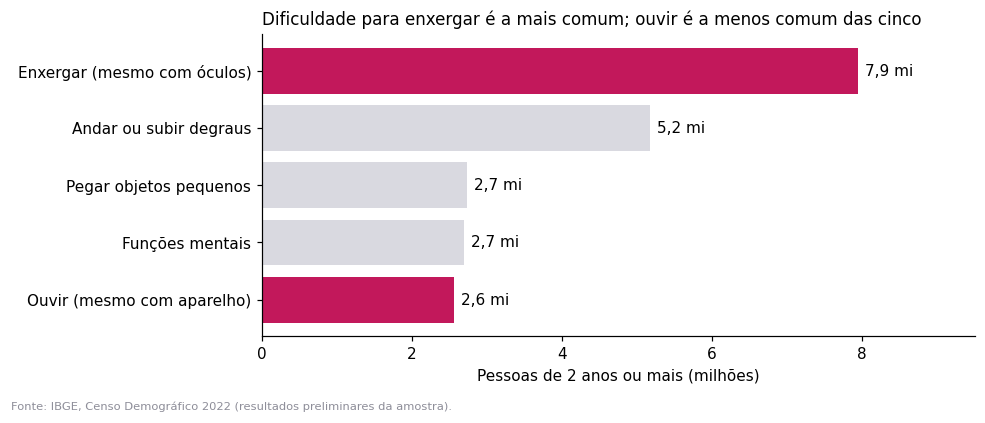

In [24]:
NOMES = {"enxergar": "Enxergar (mesmo com óculos)", "ouvir": "Ouvir (mesmo com aparelho)",
         "andar": "Andar ou subir degraus", "pegar_objetos": "Pegar objetos pequenos",
         "funcoes_mentais": "Funções mentais"}

pop_br = valor("Brasil", "pop_2mais_mil", "total", "total")
pcd_br = valor("Brasil", "pessoas_dif_funcional_mil", "total")

p1 = pd.DataFrame({"dificuldade": [NOMES[d] for d in DOMINIOS],
                   "pessoas_mil": [valor("Brasil", "pessoas_dif_funcional_mil", d) for d in DOMINIOS]})
p1["% da população"] = (p1["pessoas_mil"] / pop_br * 100).round(1)
p1["% das pessoas com deficiência"] = (p1["pessoas_mil"] / pcd_br * 100).round(1)
p1 = p1.sort_values("pessoas_mil", ascending=False).reset_index(drop=True)
print(f"População de 2 anos ou mais: {br(pop_br, 0)} mil | pessoas com deficiência: {br(pcd_br, 0)} mil ({br(pcd_br / pop_br * 100)}%)\n")
display(p1)

enx = valor("Brasil", "pessoas_dif_funcional_mil", "enxergar")
ouv = valor("Brasil", "pessoas_dif_funcional_mil", "ouvir")
limite_inf, limite_sup = max(enx, ouv), enx + ouv
print(f"Quem declara dificuldade para enxergar OU ouvir: no mínimo {br(limite_inf, 0)} mil (se todos os que ouvem mal também enxergam mal)"
      f" e no máximo {br(limite_sup, 0)} mil (se ninguém tem as duas).")
print("A soma simples é o teto, porque há pessoas com as duas dificuldades e o Censo não informa quantas.")

ordem = p1.sort_values("pessoas_mil")
fig, ax = plt.subplots(figsize=(9, 3.8))
cores = [ROSA if ("Enxergar" in n or "Ouvir" in n) else CLARO for n in ordem["dificuldade"]]
ax.barh(ordem["dificuldade"], ordem["pessoas_mil"] / 1000, color=cores)
for y, v in enumerate(ordem["pessoas_mil"] / 1000):
    ax.text(v + 0.1, y, f"{br(v)} mi", va="center")
ax.set_xlabel("Pessoas de 2 anos ou mais (milhões)")
ax.set_title("Dificuldade para enxergar é a mais comum; ouvir é a menos comum das cinco", loc="left", fontsize=11)
ax.set_xlim(0, 9.5)
rodape(fig); fig.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

**O que os dados mostram:** Em 2022, 14,4 milhões de pessoas (7,3% da população de 2 anos ou mais) tinham deficiência pela definição do Censo. A dificuldade para **enxergar** é a mais comum (7,9 milhões, 55% das pessoas com deficiência) e a de **ouvir** é a menos comum entre as cinco (2,6 milhões, 18%).

**Interpretação.** Os dois grupos são numerosos, e o de pessoas com dificuldade visual é cerca de três vezes maior que o de dificuldade auditiva. Quem declara uma dessas dificuldades pode ser 7,9 a 10,5 milhões de pessoas. **Isso não é o número de usuários do PULSO**: nem todos têm dificuldade para perceber uma chamada, e o Censo não mede isso.

### P2. Quão graves são essas dificuldades?
O Censo pergunta em quatro graus. Só "não consegue de modo algum" e "muita dificuldade" contam como deficiência; "alguma dificuldade" fica de fora da definição.

,não consegue de modo algum (%),muita dificuldade (%),alguma dificuldade (%),nenhuma (%)
Enxergar (mesmo com óculos),0.4,3.6,14.0,82.0
Ouvir (mesmo com aparelho),0.3,1.0,3.7,95.1
Andar ou subir degraus,0.6,2.0,4.3,93.1
Pegar objetos pequenos,0.4,1.0,2.4,96.2
Funções mentais,0.5,0.9,1.9,96.8


,com deficiência (mil),não consegue de modo algum (mil),muita dificuldade (mil) [derivado],% que não consegue de modo algum
Enxergar,7942.0,823.0,7119.0,10.4
Ouvir,2555.0,543.8,2011.2,21.3


Conferência: muita dificuldade para enxergar = 7.119 mil, coerente com os 7,1 milhões do texto do IBGE.
Incapacidade total para ouvir ou enxergar: entre 823 mil e 1.367 mil pessoas (soma simples = teto).


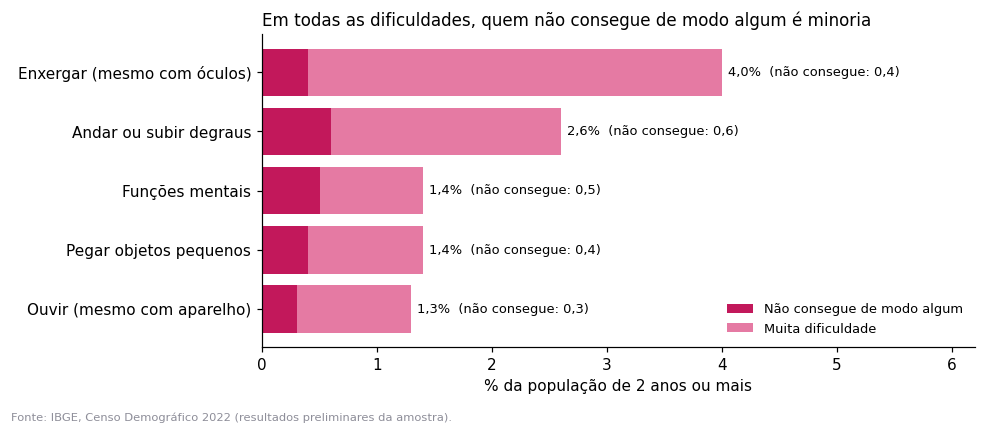

In [25]:
GRAUS = ["nao_consegue", "muita", "alguma", "nenhuma"]
graus = (df[df["indicador"] == "pct_grau_dificuldade"]
         .pivot(index="categoria", columns="subcategoria", values="valor").loc[DOMINIOS, GRAUS])
graus.index = [NOMES[d] for d in graus.index]
graus.columns = ["não consegue de modo algum (%)", "muita dificuldade (%)", "alguma dificuldade (%)", "nenhuma (%)"]
display(graus)

nc_enx = valor("Brasil", "pessoas_nao_consegue_mil", "enxergar")
nc_ouv = valor("Brasil", "pessoas_nao_consegue_mil", "ouvir")
resumo = pd.DataFrame({
    "com deficiência (mil)": [enx, ouv],
    "não consegue de modo algum (mil)": [nc_enx, nc_ouv],
    "muita dificuldade (mil) [derivado]": [enx - nc_enx, ouv - nc_ouv],
}, index=["Enxergar", "Ouvir"])
resumo["% que não consegue de modo algum"] = (resumo["não consegue de modo algum (mil)"] / resumo["com deficiência (mil)"] * 100).round(1)
display(resumo)

# conferência: o derivado para enxergar deve ficar perto dos 7,1 milhões que o texto do IBGE cita
assert abs((enx - nc_enx) - 7100) <= 100
print(f"Conferência: muita dificuldade para enxergar = {br(enx - nc_enx, 0)} mil, coerente com os 7,1 milhões do texto do IBGE.")
print(f"Incapacidade total para ouvir ou enxergar: entre {br(max(nc_enx, nc_ouv), 0)} mil e {br(nc_enx + nc_ouv, 0)} mil pessoas (soma simples = teto).")

ordem_d = sorted(DOMINIOS, key=lambda d: valor("Brasil", "pct_dif_funcional", d))
fig, ax = plt.subplots(figsize=(9, 3.9))
y = np.arange(len(ordem_d))
nc = np.array([valor("Brasil", "pct_grau_dificuldade", d, "nao_consegue") for d in ordem_d])
mu = np.array([valor("Brasil", "pct_grau_dificuldade", d, "muita") for d in ordem_d])
ax.barh(y, nc, color=ROSA, label="Não consegue de modo algum")
ax.barh(y, mu, left=nc, color="#E57AA3", label="Muita dificuldade")
for yi, (a, b) in enumerate(zip(nc, mu)):
    ax.text(a + b + 0.05, yi, f"{br(a + b)}%  (não consegue: {br(a)})", va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels([NOMES[d] for d in ordem_d])
ax.set_xlabel("% da população de 2 anos ou mais"); ax.set_xlim(0, 6.2); virgula(ax)
ax.set_title("Em todas as dificuldades, quem não consegue de modo algum é minoria", loc="left", fontsize=11)
ax.legend(loc="lower right", fontsize=8.5, frameon=False)
rodape(fig); fig.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

**O que os dados mostram.** Entre as pessoas com dificuldade para **ouvir**, cerca de 21% (543,8 mil) não conseguem ouvir de modo algum; entre as com dificuldade para **enxergar**, cerca de 10% (823 mil) não conseguem enxergar de modo algum. A maioria, nos dois casos, declara *muita dificuldade*.

**Interpretação.** O grupo de limitação total é menor (entre cerca de 0,8 e 1,4 milhão de pessoas, pela sobreposição possível), mas o de "muita dificuldade" é muito maior, e essas pessoas podem perceber parte dos sinais. Isso reforça a ideia de **alertas adaptáveis por pessoa** (vibração, luz, áudio ou combinações), em vez de um único canal. **Limite:** o Censo não diz quais canais cada pessoa consegue perceber.

### P3. Como as taxas variam entre UFs e regiões? Onde fica São Paulo?
As UFs são comparadas pela **porcentagem da população de 2 anos ou mais** (Tabelas 3 e 9). A média simples das 27 UFs **não é ponderada pela população**, portanto não é a taxa nacional; por isso mostramos os dois valores.

In [26]:
colunas = {"pct_def_total": "Deficiência (qualquer)", "pct_enxergar": "Enxergar", "pct_ouvir": "Ouvir"}
est = uf[list(colunas)].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
est.columns = ["média", "desvio-padrão", "mínimo", "Q1", "mediana", "Q3", "máximo"]
est["amplitude"] = est["máximo"] - est["mínimo"]
est["coef. variação (%)"] = est["desvio-padrão"] / est["média"] * 100
est["Brasil (publicado)"] = [valor("Brasil", "pct_com_deficiencia", "total"),
                              valor("Brasil", "pct_dif_funcional", "enxergar"),
                              valor("Brasil", "pct_dif_funcional", "ouvir")]
est.index = list(colunas.values())
print("Estatísticas descritivas entre as 27 UFs (% da população de 2 anos ou mais)")
display(est.round(2))

for col, nome in [("pct_enxergar", "enxergar"), ("pct_ouvir", "ouvir")]:
    print(f"\nMaiores taxas para {nome}:", ", ".join(f"{r.sigla} {br(getattr(r, col))}%" for r in uf.sort_values([col, "sigla"], ascending=[False, True]).head(5).itertuples()))
    print(f"Menores taxas para {nome}:", ", ".join(f"{r.sigla} {br(getattr(r, col))}%" for r in uf.sort_values([col, "sigla"]).head(5).itertuples()))

uf["posto_enxergar"] = uf["pct_enxergar"].rank(ascending=False, method="min").astype(int)
uf["posto_ouvir"] = uf["pct_ouvir"].rank(ascending=False, method="min").astype(int)
sp = uf[uf["sigla"] == "SP"].iloc[0]
print(f"\nSão Paulo: deficiência {br(sp.pct_def_total)}%, enxergar {br(sp.pct_enxergar)}% (posto {sp.posto_enxergar} de 27 UFs, 1 = maior taxa), "
      f"ouvir {br(sp.pct_ouvir)}% (posto {sp.posto_ouvir} de 27).")

Estatísticas descritivas entre as 27 UFs (% da população de 2 anos ou mais)


,média,desvio-padrão,mínimo,Q1,mediana,Q3,máximo,amplitude,coef. variação (%),Brasil (publicado)
Deficiência (qualquer),7.41,1.11,5.6,6.7,7.2,8.35,9.6,4.0,15.01,7.3
Enxergar,4.24,0.70,3.0,3.6,4.2,4.75,5.4,2.4,16.48,4.0
Ouvir,1.26,0.17,1.0,1.1,1.2,1.40,1.6,0.6,13.85,1.3



Maiores taxas para enxergar: AL 5,4%, PI 5,3%, CE 5,2%, PE 5,1%, MA 5,0%
Menores taxas para enxergar: SC 3,0%, MT 3,3%, PR 3,3%, SP 3,3%, DF 3,5%

Maiores taxas para ouvir: PI 1,6%, CE 1,5%, PB 1,5%, RN 1,5%, RS 1,5%
Menores taxas para ouvir: AM 1,0%, AP 1,0%, RR 1,0%, AC 1,1%, DF 1,1%

São Paulo: deficiência 6,3%, enxergar 3,3% (posto 24 de 27 UFs, 1 = maior taxa), ouvir 1,2% (posto 14 de 27).


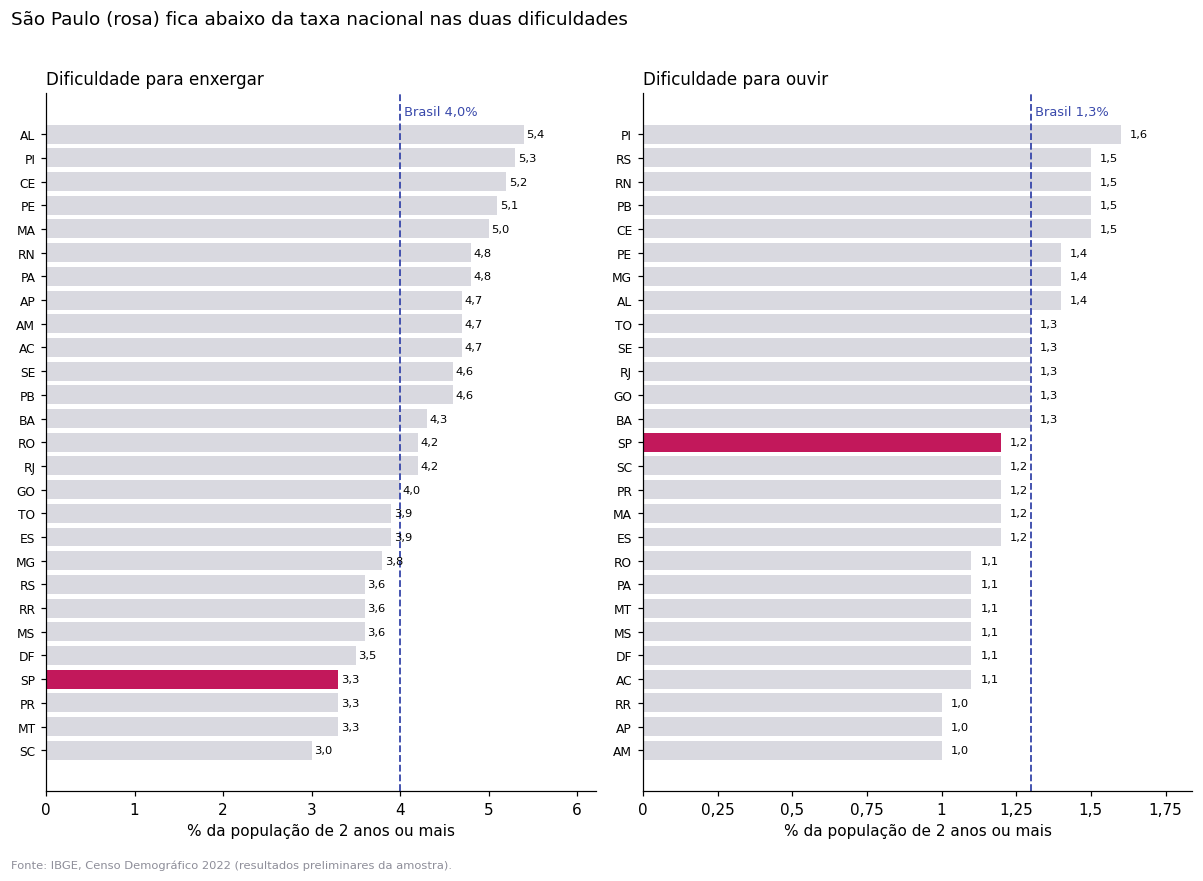

In [27]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 8), sharey=False)
for ax, col, nome in [(eixos[0], "pct_enxergar", "Dificuldade para enxergar"), (eixos[1], "pct_ouvir", "Dificuldade para ouvir")]:
    ordenado = uf.sort_values([col, "sigla"])
    cores_uf = [ROSA if s == "SP" else CLARO for s in ordenado["sigla"]]
    ax.barh(ordenado["sigla"], ordenado[col], color=cores_uf)
    ref = valor("Brasil", "pct_dif_funcional", col.replace("pct_", ""))
    ax.axvline(ref, color=AZUL, linestyle="--", linewidth=1.2)
    ax.text(ref, len(ordenado) - 0.3, f" Brasil {br(ref)}%", color=AZUL, fontsize=8.5, va="bottom")
    for y, v in enumerate(ordenado[col]):
        ax.text(v + 0.03, y, br(v), va="center", fontsize=7.5)
    ax.set_title(nome, loc="left", fontsize=11)
    ax.set_xlabel("% da população de 2 anos ou mais")
    ax.set_xlim(0, ordenado[col].max() * 1.15); virgula(ax)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("São Paulo (rosa) fica abaixo da taxa nacional nas duas dificuldades", x=0.01, ha="left", fontsize=12)
rodape(fig); fig.tight_layout(rect=(0, 0.02, 1, 0.97)); plt.show()

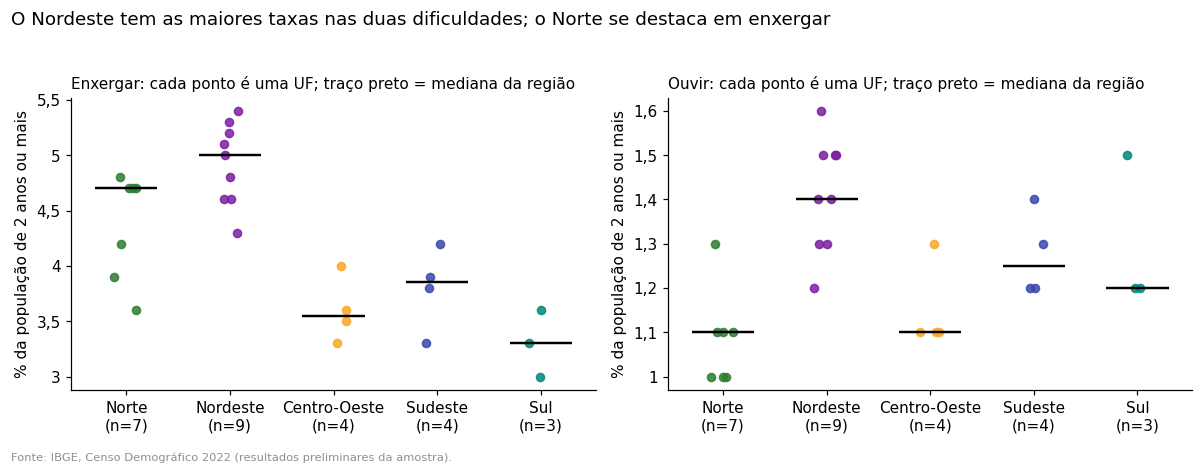

Taxa regional publicada pelo IBGE (Tabela 8), % da população de 2 anos ou mais:


,enxergar,ouvir
Brasil,4.0,1.3
Norte,4.6,1.1
Nordeste,4.8,1.4
Centro-Oeste,3.7,1.2
Sudeste,3.6,1.3
Sul,3.3,1.3


In [28]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
rng = np.random.default_rng(7)
for ax, col, nome in [(eixos[0], "pct_enxergar", "Enxergar"), (eixos[1], "pct_ouvir", "Ouvir")]:
    for i, reg in enumerate(ORDEM_REGIOES):
        v = uf.loc[uf["regiao"] == reg, col].to_numpy()
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, color=COR_REGIAO[reg], s=28, alpha=0.85, zorder=3)
        ax.hlines(np.median(v), i - 0.3, i + 0.3, color="black", linewidth=1.6, zorder=4)
    ax.set_xticks(range(len(ORDEM_REGIOES)))
    ax.set_xticklabels([f"{r}\n(n={(uf['regiao'] == r).sum()})" for r in ORDEM_REGIOES]); virgula(ax, "y")
    ax.set_ylabel("% da população de 2 anos ou mais")
    ax.set_title(f"{nome}: cada ponto é uma UF; traço preto = mediana da região", loc="left", fontsize=10)
fig.suptitle("O Nordeste tem as maiores taxas nas duas dificuldades; o Norte se destaca em enxergar", x=0.01, ha="left", fontsize=12)
rodape(fig); fig.tight_layout(rect=(0, 0.03, 1, 0.95)); plt.show()

print("Taxa regional publicada pelo IBGE (Tabela 8), % da população de 2 anos ou mais:")
reg_tab = pd.DataFrame({r: {"enxergar": valor(r, "pct_dif_funcional", "enxergar"), "ouvir": valor(r, "pct_dif_funcional", "ouvir")}
                        for r in ["Brasil"] + ORDEM_REGIOES}).T
display(reg_tab)

**O que os dados mostram:** A dificuldade para **enxergar** varia bastante entre as UFs (de 3,0% em SC a 5,4% em AL) e é maior no Nordeste e no Norte. A de **ouvir** é mais homogênea (de 1,0% a 1,6%), e as regiões ficam próximas. **São Paulo** tem taxa menor que a nacional nas duas dificuldades (enxergar 3,3% contra 4,0%; ouvir 1,2% contra 1,3%).

**Interpretação.** O público potencial existe **em todas as UFs**, sem concentração em um só lugar, o que combina com uma solução pensada para uso em qualquer estabelecimento.  
**Cuidado:** uma taxa menor em SP não significa poucas pessoas. SP é o estado mais populoso, e este CSV traz só percentuais por UF, portanto **não conseguimos calcular o número absoluto de pessoas em SP**. As diferenças de ouvir entre UFs são de poucos décimos de ponto e podem refletir arredondamento e erro amostral, então devem ser lidas com cautela.

### P4. Dificuldade para ouvir e para enxergar crescem juntas entre as UFs?
Calculamos a correlação entre as taxas das 27 UFs. É uma medida descritiva **entre territórios**: não diz nada sobre se as mesmas pessoas têm as duas dificuldades.

Correlação de Pearson entre as taxas das 27 UFs:


,enxergar,ouvir,andar,pegar objetos,funções mentais,deficiência total
enxergar,1.00,0.37,0.53,0.58,0.65,0.87
ouvir,0.37,1.00,0.86,0.83,0.86,0.73
andar,0.53,0.86,1.00,0.97,0.92,0.87
pegar objetos,0.58,0.83,0.97,1.00,0.90,0.88
funções mentais,0.65,0.86,0.92,0.90,1.00,0.91
deficiência total,0.87,0.73,0.87,0.88,0.91,1.00



Enxergar x ouvir: Pearson r = 0,37 | Spearman rho = 0,35 (n = 27 UFs)


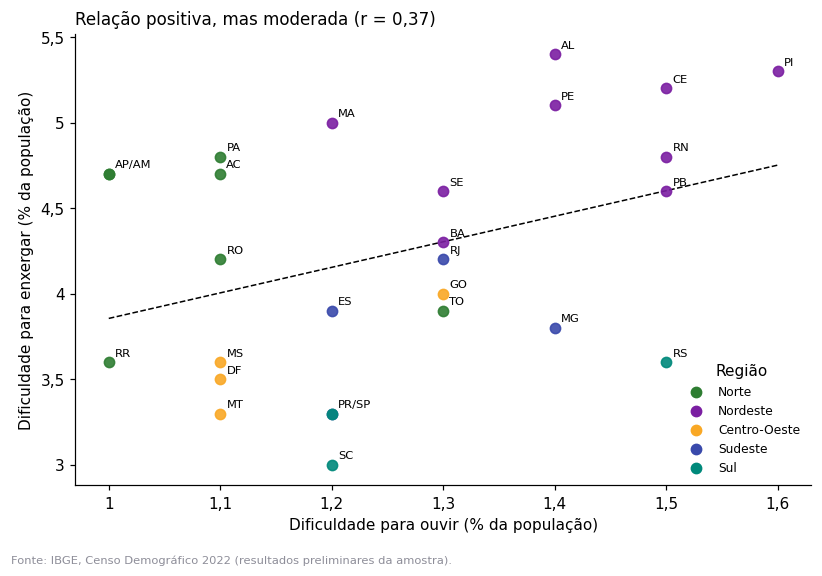

In [29]:
cols_corr = ["pct_enxergar", "pct_ouvir", "pct_andar", "pct_pegar_objetos", "pct_funcoes_mentais", "pct_def_total"]
rotulos_corr = ["enxergar", "ouvir", "andar", "pegar objetos", "funções mentais", "deficiência total"]
pearson = uf[cols_corr].corr(method="pearson"); pearson.index = pearson.columns = rotulos_corr
spearman = uf[cols_corr].corr(method="spearman"); spearman.index = spearman.columns = rotulos_corr
print("Correlação de Pearson entre as taxas das 27 UFs:")
display(pearson.round(2))

r = pearson.loc["enxergar", "ouvir"]
rho = spearman.loc["enxergar", "ouvir"]
print(f"\nEnxergar x ouvir: Pearson r = {br(r, 2)} | Spearman rho = {br(rho, 2)} (n = {len(uf)} UFs)")

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for reg in ORDEM_REGIOES:
    d = uf[uf["regiao"] == reg]
    ax.scatter(d["pct_ouvir"], d["pct_enxergar"], color=COR_REGIAO[reg], s=45, zorder=3, alpha=0.9)
    ax.scatter([], [], color=COR_REGIAO[reg], s=45, label=reg)
for (x_, y_), grupo in uf.groupby(["pct_ouvir", "pct_enxergar"]):
    ax.annotate("/".join(grupo["sigla"]), (x_, y_), xytext=(4, 4), textcoords="offset points", fontsize=7.5)
coef = np.polyfit(uf["pct_ouvir"], uf["pct_enxergar"], 1)
xs = np.linspace(uf["pct_ouvir"].min(), uf["pct_ouvir"].max(), 50)
ax.plot(xs, np.polyval(coef, xs), color="black", linewidth=1, linestyle="--", zorder=2)
ax.set_xlabel("Dificuldade para ouvir (% da população)")
ax.set_ylabel("Dificuldade para enxergar (% da população)")
ax.set_title(f"Relação positiva, mas moderada (r = {br(r, 2)})", loc="left", fontsize=11)
ax.legend(title="Região", fontsize=8, frameon=False, loc="lower right"); virgula(ax, "x"); virgula(ax, "y")
rodape(fig); fig.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

**O que os dados mostram.** A correlação entre as taxas de enxergar e de ouvir nas 27 UFs é **positiva, mas moderada** (r = 0,37; Spearman 0,35). O Nordeste fica no alto das duas escalas. O **Norte foge do padrão**: tem das maiores taxas de dificuldade para enxergar (AM, AP, PA e AC, entre 4,7% e 4,8%) com as menores de ouvir (1,0% a 1,1%).

**Interpretação:** As taxas de dificuldade auditiva e visual apresentam correlação positiva moderada entre as 27 unidades da Federação, mas suas distribuições territoriais não são idênticas. Essa associação não permite afirmar que as mesmas pessoas apresentam ambas as dificuldades.  
**Limites:** os percentuais são arredondados a uma casa decimal, a correlação não demonstra causalidade e o Censo não informa a sobreposição entre as duas dificuldades.

### P5. Há diferenças por sexo e por idade?

In [30]:
gap = uf.sort_values("diff_mulheres_homens")
print(f"UFs em que a taxa de mulheres supera a de homens: {(uf['diff_mulheres_homens'] > 0).sum()} de {len(uf)}")
print("Diferença (mulheres menos homens), em pontos percentuais:")
display(uf["diff_mulheres_homens"].describe()[["mean", "50%", "min", "max"]].rename({"mean": "média", "50%": "mediana", "min": "mínimo", "max": "máximo"}).round(2).to_frame("p.p."))
print("Maior diferença:", ", ".join(f"{r.sigla} (+{br(r.diff_mulheres_homens)})" for r in gap.tail(3).iloc[::-1].itertuples()))
print("Menor diferença:", ", ".join(f"{r.sigla} (+{br(r.diff_mulheres_homens)})" for r in gap.head(3).itertuples()))

h_tot, h_com = valor("Brasil", "pop_2mais_mil", "homens", "total"), valor("Brasil", "pop_2mais_mil", "homens", "com_deficiencia")
m_tot, m_com = valor("Brasil", "pop_2mais_mil", "mulheres", "total"), valor("Brasil", "pop_2mais_mil", "mulheres", "com_deficiencia")
print(f"\nBrasil: deficiência em {br(h_com / h_tot * 100)}% dos homens e {br(m_com / m_tot * 100)}% das mulheres; "
      f"mulheres são {br(m_com / (h_com + m_com) * 100)}% das pessoas com deficiência.")

idade = df[df["indicador"] == "pct_com_deficiencia_por_idade"].pivot(index="categoria", columns="subcategoria", values="valor")
comp = df[df["indicador"] == "pct_distribuicao_por_idade"].pivot(index="categoria", columns="subcategoria", values="valor")
print("\nPrevalência de deficiência (qualquer tipo) por idade e sexo, Brasil (%):")
display(idade.loc[["2a14", "15a59", "60a69", "70mais"], ["total", "homens", "mulheres"]])
print("Idosos (60 anos ou mais) entre as pessoas com deficiência: %s%%" % br(comp.loc[["60a79", "80mais"], "com_deficiencia"].sum()))

UFs em que a taxa de mulheres supera a de homens: 27 de 27
Diferença (mulheres menos homens), em pontos percentuais:


,p.p.
média,1.56
mediana,1.60
mínimo,0.70
máximo,2.60


Maior diferença: AL (+2,6), PE (+2,4), SE (+2,4)
Menor diferença: RR (+0,7), AP (+0,8), RO (+0,9)

Brasil: deficiência em 6,4% dos homens e 8,1% das mulheres; mulheres são 57,3% das pessoas com deficiência.

Prevalência de deficiência (qualquer tipo) por idade e sexo, Brasil (%):


subcategoria,total,homens,mulheres
categoria,,,
2a14,2.2,2.4,2.0
15a59,5.4,NaN,NaN
60a69,NaN,13.0,15.7
70mais,27.5,24.9,29.5


Idosos (60 anos ou mais) entre as pessoas com deficiência: 45,4%


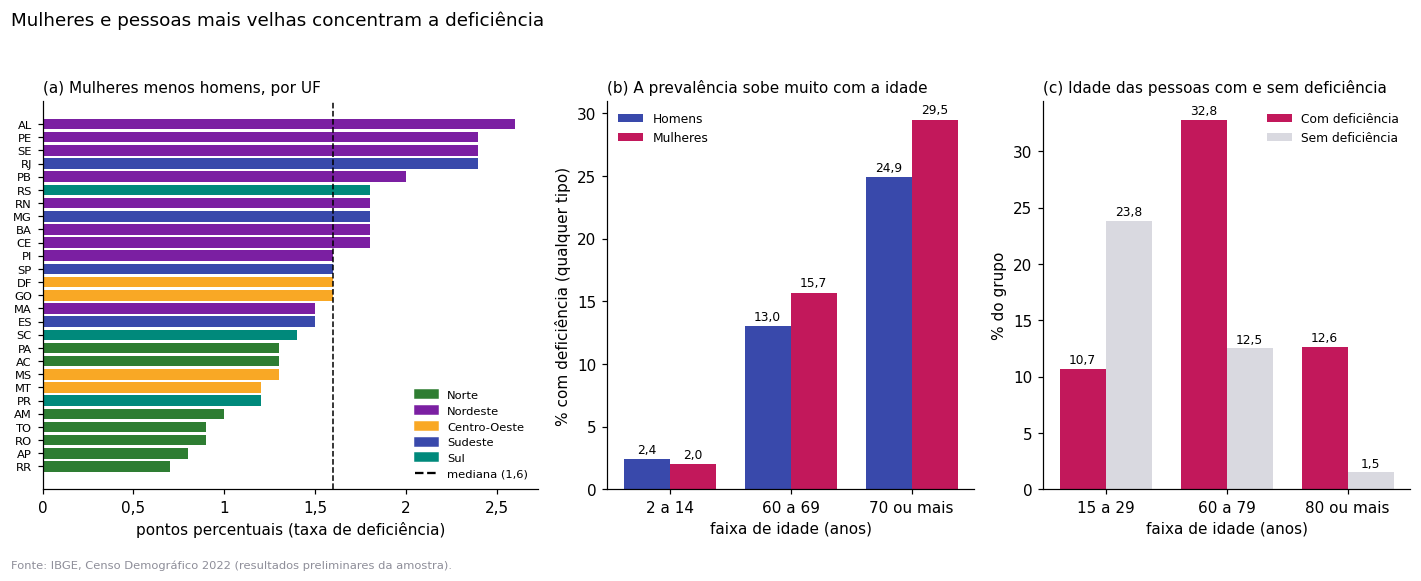

In [31]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.35, 1, 1]})

# (a) diferença mulheres - homens por UF
ax = eixos[0]
ax.barh(gap["sigla"], gap["diff_mulheres_homens"], color=[COR_REGIAO[r] for r in gap["regiao"]])
ax.axvline(gap["diff_mulheres_homens"].median(), color="black", linestyle="--", linewidth=1)
ax.set_title("(a) Mulheres menos homens, por UF", loc="left", fontsize=10)
ax.set_xlabel("pontos percentuais (taxa de deficiência)"); ax.tick_params(axis="y", labelsize=7.5)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
ax.legend(handles=[Patch(color=COR_REGIAO[r], label=r) for r in ORDEM_REGIOES]
          + [Line2D([0], [0], color="black", linestyle="--", label=f"mediana ({br(gap['diff_mulheres_homens'].median())})")],
          fontsize=7.5, frameon=False, loc="lower right")
virgula(ax)

# (b) prevalência por idade e sexo
ax = eixos[1]
grupos = ["2a14", "60a69", "70mais"]; nomes_g = ["2 a 14", "60 a 69", "70 ou mais"]
x = np.arange(len(grupos)); larg = 0.38
hom = [idade.loc[g, "homens"] for g in grupos]; mul = [idade.loc[g, "mulheres"] for g in grupos]
ax.bar(x - larg / 2, hom, larg, color=AZUL, label="Homens")
ax.bar(x + larg / 2, mul, larg, color=ROSA, label="Mulheres")
for xi, (a, b) in enumerate(zip(hom, mul)):
    ax.text(xi - larg / 2, a + 0.5, br(a), ha="center", fontsize=8); ax.text(xi + larg / 2, b + 0.5, br(b), ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(nomes_g); ax.set_xlabel("faixa de idade (anos)")
ax.set_ylabel("% com deficiência (qualquer tipo)"); ax.set_title("(b) A prevalência sobe muito com a idade", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)

# (c) composição por idade: com x sem deficiência
ax = eixos[2]
gc = ["15a29", "60a79", "80mais"]; nomes_c = ["15 a 29", "60 a 79", "80 ou mais"]
x = np.arange(len(gc))
ax.bar(x - larg / 2, [comp.loc[g, "com_deficiencia"] for g in gc], larg, color=ROSA, label="Com deficiência")
ax.bar(x + larg / 2, [comp.loc[g, "sem_deficiencia"] for g in gc], larg, color=CLARO, label="Sem deficiência")
for xi, g in enumerate(gc):
    ax.text(xi - larg / 2, comp.loc[g, "com_deficiencia"] + 0.5, br(comp.loc[g, "com_deficiencia"]), ha="center", fontsize=8)
    ax.text(xi + larg / 2, comp.loc[g, "sem_deficiencia"] + 0.5, br(comp.loc[g, "sem_deficiencia"]), ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(nomes_c); ax.set_xlabel("faixa de idade (anos)")
ax.set_ylabel("% do grupo"); ax.set_title("(c) Idade das pessoas com e sem deficiência", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)

fig.suptitle("Mulheres e pessoas mais velhas concentram a deficiência", x=0.01, ha="left", fontsize=12)
rodape(fig); fig.tight_layout(rect=(0, 0.03, 1, 0.95)); plt.show()

**O que os dados mostram.** Em **todas as 27 UFs** a taxa de deficiência é maior entre as mulheres que entre os homens (diferença mediana de 1,6 ponto percentual, de 0,7 em RR a 2,6 em AL). No Brasil, 8,1% das mulheres e 6,4% dos homens têm deficiência. A idade pesa muito: a prevalência vai de 2,2% (2 a 14 anos) para 27,5% (70 anos ou mais), e as pessoas com 60 anos ou mais são 45,4% das pessoas com deficiência, contra cerca de 14% das sem deficiência.

**Interpretação.** O perfil provável de quem enfrenta essas dificuldades inclui **muitas mulheres e muitos idosos**. Para o PULSO, isso aponta para um dispositivo simples de usar e confortável, e para a importância de interações curtas. **Limite importante:** os dados de idade e sexo desta seção valem para **deficiência em geral** (qualquer das cinco dificuldades), e não só para ouvir ou enxergar; a publicação não traz o corte por idade específico para ouvir e enxergar.

### P6. Entre as pessoas com deficiência, qual a taxa de analfabetismo?
Se uma parte grande das pessoas com deficiência não lê, um alerta que dependa de texto deixa de funcionar para elas. O dado vale para **pessoas com deficiência em geral**, de 15 anos ou mais.

Taxa de analfabetismo, Brasil:


,com deficiência (%),sem deficiência (%),razão (com / sem)
15 anos ou mais,21.3,5.2,4.1
60 anos ou mais,27.9,14.3,2.0
18 a 24 anos,12.4,1.0,12.4


Nordeste: 32,3% entre pessoas com deficiência contra 10,7% entre as sem deficiência (razão 3,0).


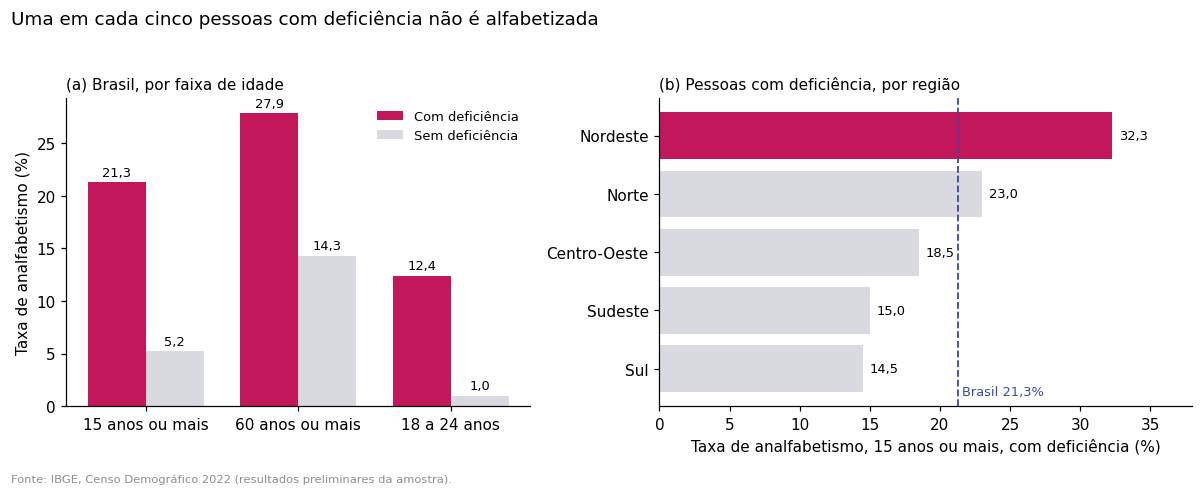

In [32]:
analf = df[df["indicador"] == "taxa_analfabetismo"]
br_tab = analf[analf["territorio"] == "Brasil"].pivot(index="categoria", columns="subcategoria", values="valor").loc[["15mais", "60mais", "18a24"]]
br_tab["razão (com / sem)"] = (br_tab["com_deficiencia"] / br_tab["sem_deficiencia"]).round(1)
br_tab.index = ["15 anos ou mais", "60 anos ou mais", "18 a 24 anos"]
br_tab.columns = ["com deficiência (%)", "sem deficiência (%)", "razão (com / sem)"]
print("Taxa de analfabetismo, Brasil:")
display(br_tab)

reg_com = analf[(analf["nivel"] == "Região") & (analf["subcategoria"] == "com_deficiencia")].set_index("territorio")["valor"].reindex(ORDEM_REGIOES)
ne_sem = valor("Nordeste", "taxa_analfabetismo", "15mais", "sem_deficiencia")
print(f"Nordeste: {br(reg_com['Nordeste'])}% entre pessoas com deficiência contra {br(ne_sem)}% entre as sem deficiência (razão {br(reg_com['Nordeste'] / ne_sem)}).")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})
ax = eixos[0]
x = np.arange(3); larg = 0.38
ax.bar(x - larg / 2, br_tab["com deficiência (%)"], larg, color=ROSA, label="Com deficiência")
ax.bar(x + larg / 2, br_tab["sem deficiência (%)"], larg, color=CLARO, label="Sem deficiência")
for xi, (a, b) in enumerate(zip(br_tab["com deficiência (%)"], br_tab["sem deficiência (%)"])):
    ax.text(xi - larg / 2, a + 0.6, br(a), ha="center", fontsize=8.5); ax.text(xi + larg / 2, b + 0.6, br(b), ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(br_tab.index); ax.set_ylabel("Taxa de analfabetismo (%)")
ax.set_title("(a) Brasil, por faixa de idade", loc="left", fontsize=10); ax.legend(frameon=False, fontsize=8.5)

ax = eixos[1]
ordem_r = reg_com.sort_values()
ax.barh(ordem_r.index, ordem_r.values, color=[ROSA if r == "Nordeste" else CLARO for r in ordem_r.index])
for y, v in enumerate(ordem_r.values):
    ax.text(v + 0.5, y, br(v), va="center", fontsize=8.5)
ref = valor("Brasil", "taxa_analfabetismo", "15mais", "com_deficiencia")
ax.axvline(ref, color=AZUL, linestyle="--", linewidth=1.2); ax.text(ref + 0.3, -0.45, f"Brasil {br(ref)}%", color=AZUL, fontsize=8.5)
ax.set_xlabel("Taxa de analfabetismo, 15 anos ou mais, com deficiência (%)"); ax.set_xlim(0, 38)
ax.set_title("(b) Pessoas com deficiência, por região", loc="left", fontsize=10)
fig.suptitle("Uma em cada cinco pessoas com deficiência não é alfabetizada", x=0.01, ha="left", fontsize=12)
rodape(fig); fig.tight_layout(rect=(0, 0.03, 1, 0.95)); plt.show()

**O que os dados mostram:** A taxa de analfabetismo de pessoas com deficiência de 15 anos ou mais é de **21,3%**, contra **5,2%** das sem deficiência (4,1 vezes). Entre 18 e 24 anos a diferença é ainda maior (12,4% contra 1,0%). No Nordeste, 32,3% das pessoas com deficiência não são alfabetizadas.

**Interpretação:** Mensagens escritas no visor ou no celular **não alcançam** uma parte importante dessas pessoas. Isso apoia a escolha do PULSO por **sinais sensoriais** (vibração, luz, som) sem depender de texto, e conecta com o relato de uma moradora surda não alfabetizada (Agência Mural, 2020).  
**Limite:** o dado é de pessoas com deficiência em geral, e não separa quem tem dificuldade auditiva ou visual.

## 6. Conclusões
As conclusões abaixo usam os valores calculados nas seções anteriores. Cada uma separa o **dado observado** da **interpretação**.

In [33]:
sp = uf[uf["sigla"] == "SP"].iloc[0]
n_mulheres_maior = int((uf["diff_mulheres_homens"] > 0).sum())
analf_com = valor("Brasil", "taxa_analfabetismo", "15mais", "com_deficiencia")
analf_sem = valor("Brasil", "taxa_analfabetismo", "15mais", "sem_deficiencia")

display(Markdown(f"""
**C1 (P1) · O grupo é grande.**
*Observado:* {br(enx, 0)} mil pessoas declaram muita dificuldade ou incapacidade para enxergar e {br(ouv, 0)} mil para ouvir (Censo 2022). Quem tem uma ou outra totaliza entre {br(limite_inf, 0)} mil e {br(limite_sup, 0)} mil, conforme a sobreposição.
*Interpretação:* o público potencial é de milhões de pessoas, mas isso **não** é o número de usuários nem de chamadas perdidas.

**C2 (P2) · A limitação total é minoria.**
*Observado:* {br(nc_ouv / ouv * 100, 0)}% de quem tem dificuldade para ouvir e {br(nc_enx / enx * 100, 0)}% de quem tem dificuldade para enxergar não conseguem de modo algum; os demais declaram muita dificuldade.
*Interpretação:* faz sentido oferecer **alertas combináveis por pessoa**, porque muita gente percebe parte dos sinais.

**C3 (P3) · Está espalhado pelo país.**
*Observado:* a taxa de dificuldade para enxergar vai de {br(uf['pct_enxergar'].min())}% a {br(uf['pct_enxergar'].max())}% entre as UFs e a de ouvir, de {br(uf['pct_ouvir'].min())}% a {br(uf['pct_ouvir'].max())}%. SP tem {br(sp.pct_enxergar)}% (enxergar) e {br(sp.pct_ouvir)}% (ouvir), abaixo da taxa nacional.
*Interpretação:* existe público em todas as UFs. Taxa menor em SP não quer dizer poucas pessoas: faltam, nesta base, os números absolutos por UF.

**C4 (P4) · Relação moderada entre os territórios.**
*Observado:* correlação de Pearson de {br(r, 2)} (Spearman {br(rho, 2)}) entre as taxas das {len(uf)} UFs: positiva, mas moderada; o Norte tem alta taxa para enxergar e baixa para ouvir.
*Interpretação:* as taxas apresentam associação territorial moderada, mas isso **não prova causalidade** nem permite determinar quantas pessoas apresentam ambas as dificuldades.

**C5 (P5) · Mulheres e idosos pesam no perfil.**
*Observado:* a taxa de deficiência é maior entre mulheres em {n_mulheres_maior} das {len(uf)} UFs; sobe de 2,2% (2 a 14 anos) para 27,5% (70 anos ou mais); 60 anos ou mais são 45,4% das pessoas com deficiência.
*Interpretação:* o desenho deve ser simples e confortável. Esses números valem para deficiência em geral, e não só para ouvir ou enxergar.

**C6 (P6) · Texto não alcança todos.**
*Observado:* {br(analf_com)}% das pessoas com deficiência de 15 anos ou mais são analfabetas, contra {br(analf_sem)}% das sem deficiência.
*Interpretação:* alertas por vibração, luz e som, sem depender de leitura, são coerentes com o público.
"""))


**C1 (P1) · O grupo é grande.**
*Observado:* 7.942 mil pessoas declaram muita dificuldade ou incapacidade para enxergar e 2.555 mil para ouvir (Censo 2022). Quem tem uma ou outra totaliza entre 7.942 mil e 10.497 mil, conforme a sobreposição.
*Interpretação:* o público potencial é de milhões de pessoas, mas isso **não** é o número de usuários nem de chamadas perdidas.

**C2 (P2) · A limitação total é minoria.**
*Observado:* 21% de quem tem dificuldade para ouvir e 10% de quem tem dificuldade para enxergar não conseguem de modo algum; os demais declaram muita dificuldade.
*Interpretação:* faz sentido oferecer **alertas combináveis por pessoa**, porque muita gente percebe parte dos sinais.

**C3 (P3) · Está espalhado pelo país.**
*Observado:* a taxa de dificuldade para enxergar vai de 3,0% a 5,4% entre as UFs e a de ouvir, de 1,0% a 1,6%. SP tem 3,3% (enxergar) e 1,2% (ouvir), abaixo da taxa nacional.
*Interpretação:* existe público em todas as UFs. Taxa menor em SP não quer dizer poucas pessoas: faltam, nesta base, os números absolutos por UF.

**C4 (P4) · Relação moderada entre os territórios.**
*Observado:* correlação de Pearson de 0,37 (Spearman 0,35) entre as taxas das 27 UFs: positiva, mas moderada; o Norte tem alta taxa para enxergar e baixa para ouvir.
*Interpretação:* as taxas apresentam associação territorial moderada, mas isso **não prova causalidade** nem permite determinar quantas pessoas apresentam ambas as dificuldades.

**C5 (P5) · Mulheres e idosos pesam no perfil.**
*Observado:* a taxa de deficiência é maior entre mulheres em 27 das 27 UFs; sobe de 2,2% (2 a 14 anos) para 27,5% (70 anos ou mais); 60 anos ou mais são 45,4% das pessoas com deficiência.
*Interpretação:* o desenho deve ser simples e confortável. Esses números valem para deficiência em geral, e não só para ouvir ou enxergar.

**C6 (P6) · Texto não alcança todos.**
*Observado:* 21,3% das pessoas com deficiência de 15 anos ou mais são analfabetas, contra 5,2% das sem deficiência.
*Interpretação:* alertas por vibração, luz e som, sem depender de leitura, são coerentes com o público.


### Ligação com o PULSO e limites desta análise
- Os dados **ajudam a dimensionar e a descrever o público** (tamanho, gravidade, distribuição, perfil e alfabetização). Eles **não demonstram** que chamadas sejam perdidas nem com que frequência: isso só aparece nos relatos e estudos qualitativos citados no início, de outros contextos e com amostras pequenas.
- Os valores são **preliminares**, de uma **amostra** do Censo, e foram **digitados** a partir da publicação (conferidos pelas verificações da seção 4.4).
- O corte por idade vale para **deficiência em geral**. Não há, nesta base, dados por município, por tipo de serviço ou sobre surdocegueira.
- Nada aqui é uma funcionalidade do PULSO: é uma análise acadêmica complementar.

## 7. Referências
- IBGE. *Censo Demográfico 2022: Pessoas com deficiência e pessoas diagnosticadas com transtorno do espectro autista: Resultados preliminares da amostra*. Rio de Janeiro: IBGE, 2025. https://biblioteca.ibge.gov.br/visualizacao/livros/liv102178.pdf
- AGÊNCIA MURAL. *Como é o atendimento em Libras na rede pública de saúde de São Paulo?* 09/03/2020.
- CARDOSO, A. H. A.; RODRIGUES, K. G.; BACHION, M. M. Percepção da pessoa com surdez severa e/ou profunda acerca do processo de comunicação durante seu atendimento de saúde. *Revista Latino-Americana de Enfermagem*, v. 14, n. 4, p. 553-560, 2006.
- LEVY et al. Experiences of culturally Deaf people with health care access and navigation in Ontario, Canada: a qualitative co-design study. *CMAJ*, v. 198, n. 28, 2026.
- RNID. *Healthcare Survey Research Note: Scotland*. Abril de 2025.